In [ ]:
# ============================================================
# VGG16 LOCAL TRAINING - SETUP + DATASET + DATALOADERS
# OcuVision-AI
# ============================================================

from pathlib import Path
import random
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 2. Find project root robustly
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

while PROJECT_ROOT.name != "OcuVision-AI" and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project root:", PROJECT_ROOT)

# ------------------------------------------------------------
# 3. Paths
# ------------------------------------------------------------

DATA_DIR = PROJECT_ROOT / "data" / "preprocessed"
RESULTS_DIR = PROJECT_ROOT / "results" / "vgg16"
MODELS_DIR = PROJECT_ROOT / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = MODELS_DIR / "vgg16_best_checkpoint.pth"
HISTORY_PATH = RESULTS_DIR / "vgg16_training_history.csv"

print("Dataset:", DATA_DIR)
print("Results:", RESULTS_DIR)
print("Checkpoint:", CHECKPOINT_PATH)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_DIR}")

# ------------------------------------------------------------
# 4. Class mapping
# Keep the SAME class order used for ResNet50
# ------------------------------------------------------------

classes = ["N", "D", "G", "C", "A", "H", "M"]

class_to_idx = {cls: idx for idx, cls in enumerate(classes)}
idx_to_class = {idx: cls for cls, idx in class_to_idx.items()}

print("\nClass mapping:")
print(class_to_idx)

# ------------------------------------------------------------
# 5. Collect image paths
# ------------------------------------------------------------

image_paths = []
labels = []

for cls in classes:
    class_dir = DATA_DIR / cls

    if not class_dir.exists():
        raise FileNotFoundError(f"Missing class directory: {class_dir}")

    for image_path in sorted(class_dir.glob("*")):
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]:
            image_paths.append(str(image_path))
            labels.append(class_to_idx[cls])

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

df["class"] = df["label"].map(idx_to_class)

print("\nTotal images:", len(df))
print("\nClass distribution:")
print(df["class"].value_counts().reindex(classes))

# ------------------------------------------------------------
# 6. Same stratified 80/10/10 split
# random_state = 42
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nDataset split:")
print(f"Train: {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test: {len(test_df)}")

print("\nExpected approximately:")
print("Train: 8359")
print("Validation: 1045")
print("Test: 1045")



# ------------------------------------------------------------
# 7. Dataset class
# ------------------------------------------------------------

class OcularDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

# ------------------------------------------------------------
# 8. VGG16 transforms
# VGG16 uses 224x224 ImageNet input
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# 9. Create datasets
# ------------------------------------------------------------

train_dataset = OcularDataset(train_df, train_transform)
val_dataset = OcularDataset(val_df, eval_transform)
test_dataset = OcularDataset(test_df, eval_transform)

# ------------------------------------------------------------
# 10. DataLoaders
# RTX 4050 6GB -> start with batch size 16
# ------------------------------------------------------------

BATCH_SIZE = 16
NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# ------------------------------------------------------------
# 11. Device
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nDevice:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

print("\nDataLoaders ready.")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Project root: D:\gpt\OcuVision-AI
Dataset: D:\gpt\OcuVision-AI\data\preprocessed
Results: D:\gpt\OcuVision-AI\results\vgg16
Checkpoint: D:\gpt\OcuVision-AI\models\vgg16_best_checkpoint.pth

Class mapping:
{'N': 0, 'D': 1, 'G': 2, 'C': 3, 'A': 4, 'H': 5, 'M': 6}

Total images: 10449

Class distribution:
class
N    2997
D    3128
G    1646
C    1008
A     511
H     420
M     739
Name: count, dtype: int64

Dataset split:
Train: 8359
Validation: 1045
Test: 1045

Expected approximately:
Train: 8359
Validation: 1045
Test: 1045


Loading pretrained VGG16...
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\chede appliances/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100%|██████████| 528M/528M [01:29<00:00, 6.19MB/s] 


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

Epoch 1/10:   0%|          | 0/523 [00:00<?, ?it/s]


Epoch 1/10 | Train Loss: 0.9621 | Train Acc: 0.6360 | Train F1: 0.5568 | Val Loss: 0.7928 | Val Acc: 0.6909 | Val Macro F1: 0.6467 | Time: 7.99 min
  ✓ Best checkpoint saved (Val Macro F1 = 0.6467)


...


Epoch 8/10 | Train Loss: 0.4227 | Train Acc: 0.8459 | Train F1: 0.8457 | Val Loss: 0.5292 | Val Acc: 0.8096 | Val Macro F1: 0.7932 | Time: 9.42 min


Epoch 9/10:   0%|          | 0/523 [00:00<?, ?it/s]


Epoch 9/10 | Train Loss: 0.3874 | Train Acc: 0.8611 | Train F1: 0.8621 | Val Loss: 0.5827 | Val Acc: 0.8096 | Val Macro F1: 0.8084 | Time: 9.80 min


Epoch 10/10:   0%|          | 0/523 [00:00<?, ?it/s]


Epoch 10/10 | Train Loss: 0.3675 | Train Acc: 0.8673 | Train F1: 0.8706 | Val Loss: 0.6025 | Val Acc: 0.7876 | Val Macro F1: 0.7437 | Time: 10.06 min

VGG16 TRAINING COMPLETE
Best validation Macro F1: 0.8273
Total training time: 1.54 hours
Checkpoint: D:\gpt\OcuVision-AI\models\vgg16_best_checkpoint.pth
History: D:\gpt\OcuVision-AI\results\vgg16\vgg16_training_history.csv


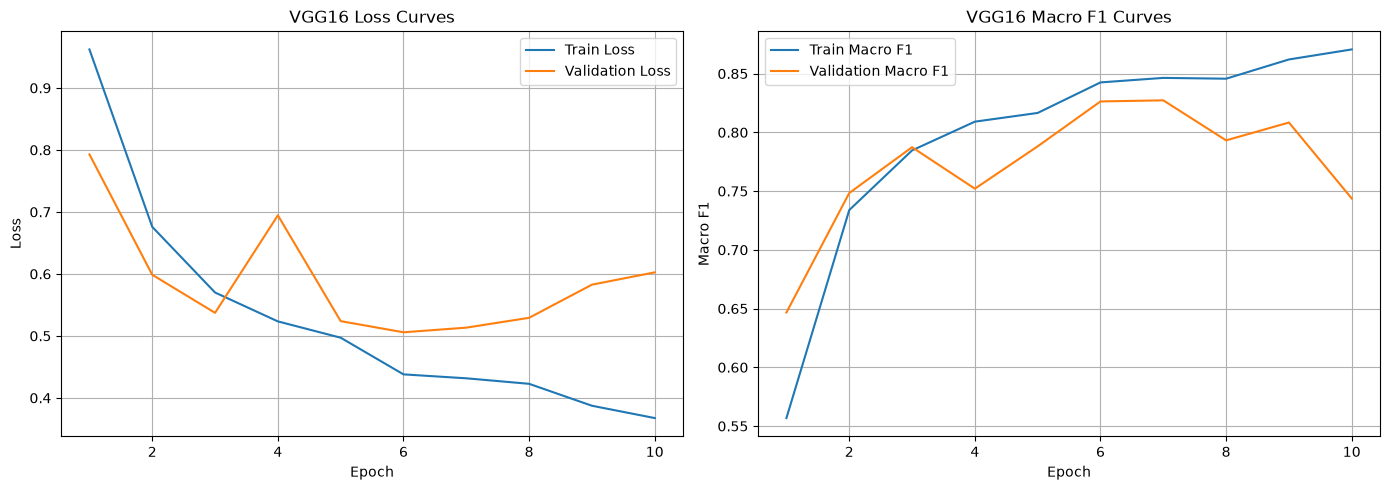

Training curve saved: D:\gpt\OcuVision-AI\results\vgg16\vgg16_training_curves.png


In [4]:
# ============================================================
# VGG16 LOCAL TRAINING
# ============================================================

import time
import matplotlib.pyplot as plt

from torchvision.models import vgg16, VGG16_Weights
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# 1. Load pretrained VGG16
# ------------------------------------------------------------

print("Loading pretrained VGG16...")

model = vgg16(
    weights=VGG16_Weights.IMAGENET1K_V1
)

# Replace final classifier for 7 ocular classes
model.classifier[6] = nn.Linear(
    model.classifier[6].in_features,
    len(classes)
)

model = model.to(device)

print(model)
print("\nModel loaded successfully.")

# ------------------------------------------------------------
# 2. Loss and optimizer
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# 3. Training configuration
# ------------------------------------------------------------

NUM_EPOCHS = 10

best_val_f1 = -1.0
history = []

# Mixed precision for CUDA
if device.type == "cuda":
    scaler = torch.amp.GradScaler("cuda")
else:
    scaler = torch.amp.GradScaler("cpu")

# ------------------------------------------------------------
# 4. Evaluation function
# ------------------------------------------------------------

def evaluate_model(model, loader):

    model.eval()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if device.type == "cuda":

                with torch.amp.autocast("cuda"):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

            else:

                outputs = model(images)
                loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    accuracy = np.mean(
        np.array(all_labels) == np.array(all_predictions)
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, accuracy, macro_f1

# ------------------------------------------------------------
# 5. Training loop
# ------------------------------------------------------------

print("\nStarting VGG16 training...")
print(f"Epochs: {NUM_EPOCHS}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Device: {device}")
print("-" * 70)

training_start = time.time()

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    model.train()

    running_loss = 0.0
    all_train_labels = []
    all_train_predictions = []

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    for images, labels in progress_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        if device.type == "cuda":

            with torch.amp.autocast("cuda"):

                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        else:

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        all_train_labels.extend(labels.detach().cpu().numpy())
        all_train_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = running_loss / len(train_loader.dataset)

    train_accuracy = np.mean(
        np.array(all_train_labels)
        == np.array(all_train_predictions)
    )

    train_macro_f1 = f1_score(
        all_train_labels,
        all_train_predictions,
        average="macro",
        zero_division=0
    )

    # Validation
    val_loss, val_accuracy, val_macro_f1 = evaluate_model(
        model,
        val_loader
    )

    epoch_time = time.time() - epoch_start

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "epoch_time_seconds": epoch_time
    })

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Train F1: {train_macro_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f} | "
        f"Time: {epoch_time/60:.2f} min"
    )

    # --------------------------------------------------------
    # Save best checkpoint based on validation Macro F1
    # --------------------------------------------------------

    if val_macro_f1 > best_val_f1:

        best_val_f1 = val_macro_f1

        checkpoint = {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch + 1,
            "best_val_macro_f1": best_val_f1,
            "classes": classes,
            "class_to_idx": class_to_idx,
            "seed": SEED
        }

        torch.save(
            checkpoint,
            CHECKPOINT_PATH
        )

        print(
            f"  ✓ Best checkpoint saved "
            f"(Val Macro F1 = {best_val_f1:.4f})"
        )

# ------------------------------------------------------------
# 6. Save training history
# ------------------------------------------------------------

history_df = pd.DataFrame(history)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

total_training_time = time.time() - training_start

print("\n" + "=" * 70)
print("VGG16 TRAINING COMPLETE")
print("=" * 70)

print(f"Best validation Macro F1: {best_val_f1:.4f}")
print(f"Total training time: {total_training_time / 3600:.2f} hours")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"History: {HISTORY_PATH}")

# ------------------------------------------------------------
# 7. Training curves
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("VGG16 Loss Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Train Macro F1"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation Macro F1"
)

axes[1].set_title("VGG16 Macro F1 Curves")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

training_curve_path = RESULTS_DIR / "vgg16_training_curves.png"

plt.savefig(
    training_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training curve saved:", training_curve_path)

Loading best VGG16 checkpoint...
✓ Best checkpoint loaded
Checkpoint epoch: 7
Best validation Macro F1: 0.8272706276268964


Evaluating VGG16 on test set:   0%|          | 0/66 [00:00<?, ?it/s]



VGG16 FINAL TEST RESULTS
Test Loss          : 0.4463
Accuracy            : 84.88%
Macro Precision     : 87.19%
Macro Recall        : 83.18%
Macro F1            : 84.88%
Weighted F1         : 84.86%

Classification Report:


,precision,recall,f1-score,support
N,0.7794,0.9067,0.8382,300.0000
D,0.8940,0.8083,0.8490,313.0000
G,0.8150,0.8598,0.8368,164.0000
C,1.0000,0.9208,0.9588,101.0000
A,0.9800,0.9608,0.9703,51.0000
H,0.8286,0.6905,0.7532,42.0000
M,0.8065,0.6757,0.7353,74.0000
accuracy,0.8488,0.8488,0.8488,0.8488
macro avg,0.8719,0.8318,0.8488,1045.0000
weighted avg,0.8543,0.8488,0.8486,1045.0000


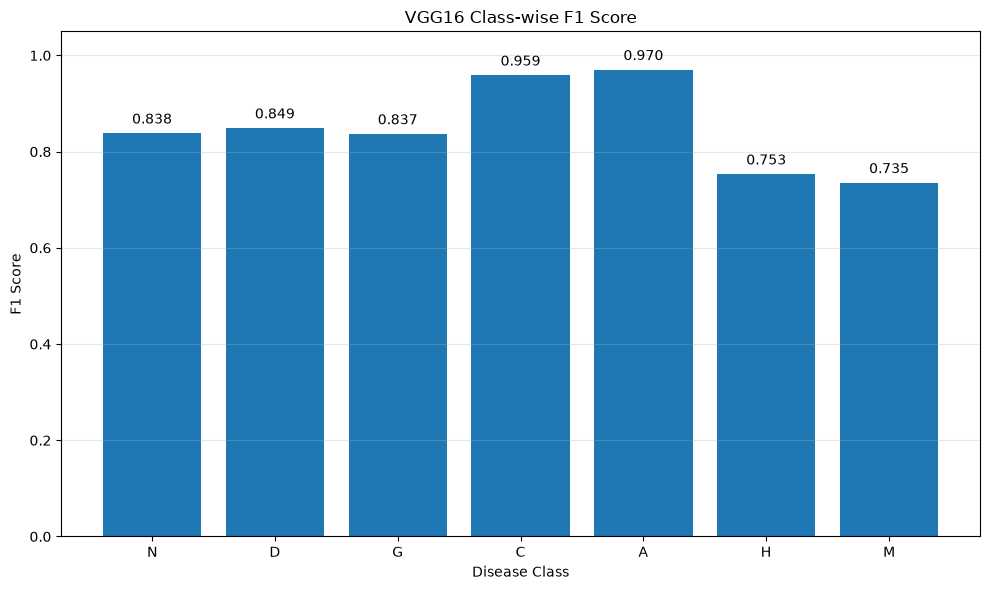

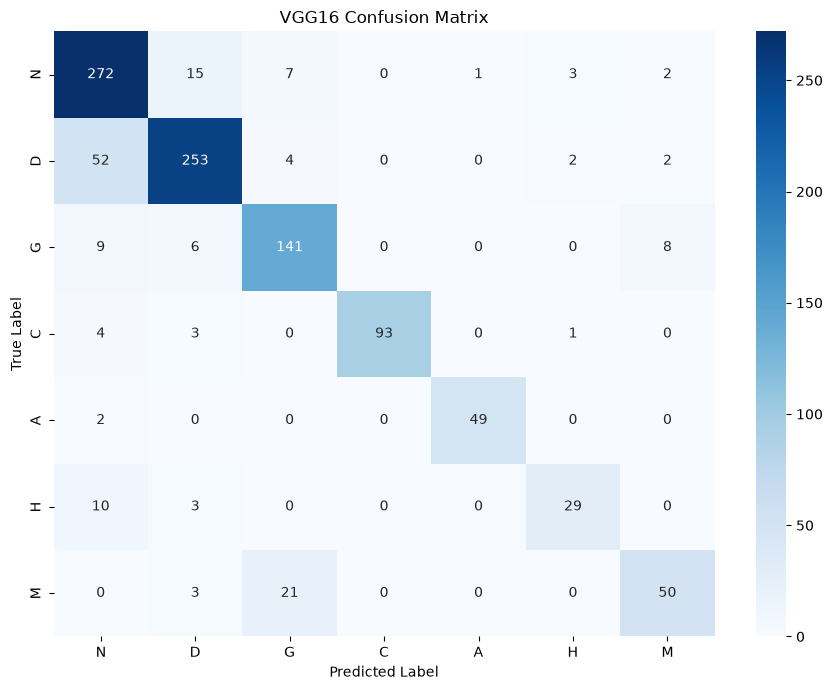

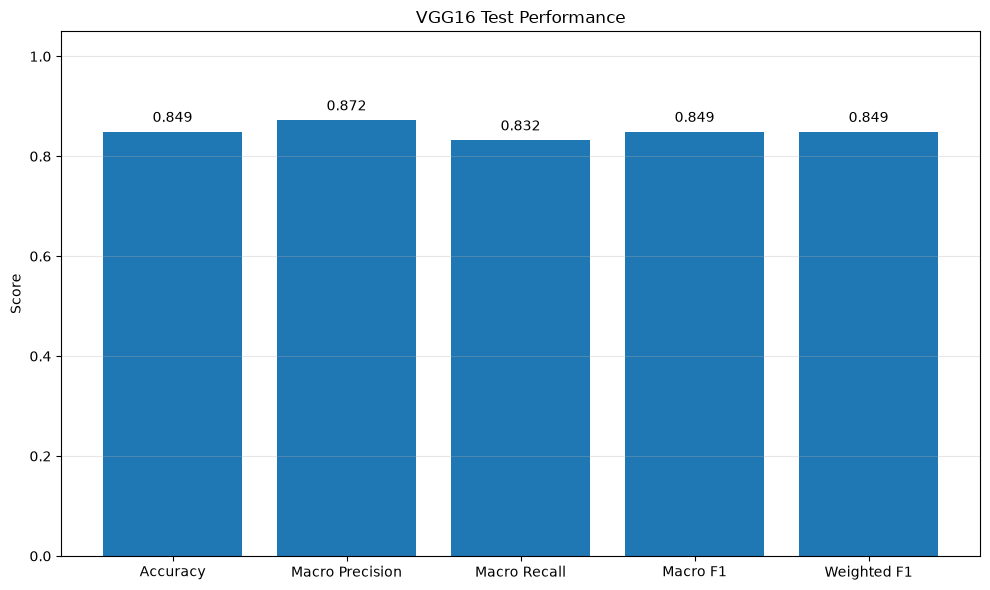



VGG16 EVALUATION COMPLETE

Results saved in:
D:\gpt\OcuVision-AI\results\vgg16

Generated files:
  ✓ vgg16_classification_report.csv
  ✓ vgg16_classwise_f1.csv
  ✓ vgg16_classwise_f1.png
  ✓ vgg16_confusion_matrix.png
  ✓ vgg16_experiment_summary.txt
  ✓ vgg16_test_metrics.csv
  ✓ vgg16_test_metrics.json
  ✓ vgg16_test_metrics.png
  ✓ vgg16_training_curves.png
  ✓ vgg16_training_history.csv

Checkpoint:
  ✓ D:\gpt\OcuVision-AI\models\vgg16_best_checkpoint.pth

FINAL VGG16 METRICS
----------------------------------------
Accuracy        : 84.88%
Macro Precision : 87.19%
Macro Recall    : 83.18%
Macro F1        : 84.88%
Weighted F1     : 84.86%


In [5]:
# ============================================================
# VGG16 COMPLETE EVALUATION + RESULTS
# OcuVision-AI
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torchvision.models import vgg16, VGG16_Weights

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Recreate VGG16 architecture
# ------------------------------------------------------------

print("Loading best VGG16 checkpoint...")

best_model = vgg16(
    weights=None
)

best_model.classifier[6] = nn.Linear(
    best_model.classifier[6].in_features,
    len(classes)
)

best_model = best_model.to(device)

# ------------------------------------------------------------
# 2. Load best checkpoint
# ------------------------------------------------------------

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT_PATH}\n\n"
        "Make sure the VGG16 training cell has finished."
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_model.eval()

print("✓ Best checkpoint loaded")
print(f"Checkpoint epoch: {checkpoint.get('epoch', 'unknown')}")
print(
    f"Best validation Macro F1: "
    f"{checkpoint.get('best_val_macro_f1', 'unknown')}"
)

# ------------------------------------------------------------
# 3. Test-set inference
# ------------------------------------------------------------

all_labels = []
all_predictions = []
all_probabilities = []

test_loss = 0.0

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Evaluating VGG16 on test set"
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if device.type == "cuda":

            with torch.amp.autocast("cuda"):
                outputs = best_model(images)
                loss = criterion(outputs, labels)

        else:

            outputs = best_model(images)
            loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

# Convert to numpy arrays

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

test_loss = test_loss / len(test_loader.dataset)

# ------------------------------------------------------------
# 4. Calculate final metrics
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# 5. Print final test results
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("VGG16 FINAL TEST RESULTS")
print("=" * 70)

print(f"Test Loss          : {test_loss:.4f}")
print(f"Accuracy            : {test_accuracy * 100:.2f}%")
print(f"Macro Precision     : {macro_precision * 100:.2f}%")
print(f"Macro Recall        : {macro_recall * 100:.2f}%")
print(f"Macro F1            : {macro_f1 * 100:.2f}%")
print(f"Weighted F1         : {weighted_f1 * 100:.2f}%")

print("=" * 70)

# ------------------------------------------------------------
# 6. Classification report
# ------------------------------------------------------------

report_dict = classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report_dict
).transpose()

classification_report_path = (
    RESULTS_DIR / "vgg16_classification_report.csv"
)

report_df.to_csv(
    classification_report_path
)

print("\nClassification Report:")
display(report_df.round(4))

# ------------------------------------------------------------
# 7. Class-wise F1 scores
# ------------------------------------------------------------

classwise_f1 = {}

for cls in classes:

    classwise_f1[cls] = report_dict[
        cls
    ]["f1-score"]

classwise_f1_df = pd.DataFrame({
    "Class": list(classwise_f1.keys()),
    "F1 Score": list(classwise_f1.values())
})

classwise_f1_path = (
    RESULTS_DIR / "vgg16_classwise_f1.csv"
)

classwise_f1_df.to_csv(
    classwise_f1_path,
    index=False
)

# Plot class-wise F1

plt.figure(figsize=(10, 6))

plt.bar(
    classwise_f1_df["Class"],
    classwise_f1_df["F1 Score"]
)

plt.ylim(0, 1.05)
plt.xlabel("Disease Class")
plt.ylabel("F1 Score")
plt.title("VGG16 Class-wise F1 Score")

for i, value in enumerate(
    classwise_f1_df["F1 Score"]
):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

classwise_f1_plot = (
    RESULTS_DIR / "vgg16_classwise_f1.png"
)

plt.savefig(
    classwise_f1_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("VGG16 Confusion Matrix")

plt.tight_layout()

confusion_matrix_path = (
    RESULTS_DIR / "vgg16_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. Test metrics plot
# ------------------------------------------------------------

metric_names = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

metric_values = [
    test_accuracy,
    macro_precision,
    macro_recall,
    macro_f1,
    weighted_f1
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    metric_names,
    metric_values
)

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("VGG16 Test Performance")

for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

test_metrics_plot = (
    RESULTS_DIR / "vgg16_test_metrics.png"
)

plt.savefig(
    test_metrics_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. Save numerical metrics
# ------------------------------------------------------------

metrics = {
    "model": "VGG16",
    "test_loss": float(test_loss),
    "accuracy": float(test_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "best_validation_macro_f1": float(
        checkpoint["best_val_macro_f1"]
    ),
    "best_epoch": int(
        checkpoint["epoch"]
    ),
    "test_samples": int(
        len(test_dataset)
    )
}

metrics_df = pd.DataFrame([
    metrics
])

metrics_csv_path = (
    RESULTS_DIR / "vgg16_test_metrics.csv"
)

metrics_df.to_csv(
    metrics_csv_path,
    index=False
)

# Also save JSON

metrics_json_path = (
    RESULTS_DIR / "vgg16_test_metrics.json"
)

with open(
    metrics_json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metrics,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 11. Experiment summary
# ------------------------------------------------------------

summary_text = f"""
VGG16 Experiment Summary
=========================

Model:
VGG16 pretrained on ImageNet

Dataset:
ODIR-5K preprocessed ocular disease dataset

Classes:
{", ".join(classes)}

Dataset split:
Train: {len(train_dataset)}
Validation: {len(val_dataset)}
Test: {len(test_dataset)}

Random seed:
{SEED}

Input size:
224 x 224

Batch size:
{BATCH_SIZE}

Optimizer:
AdamW

Learning rate:
1e-4

Weight decay:
1e-4

Number of epochs:
{NUM_EPOCHS}

Best validation epoch:
{checkpoint["epoch"]}

Best validation Macro F1:
{checkpoint["best_val_macro_f1"] * 100:.2f}%

Final Test Results
------------------

Test Loss:
{test_loss:.4f}

Accuracy:
{test_accuracy * 100:.2f}%

Macro Precision:
{macro_precision * 100:.2f}%

Macro Recall:
{macro_recall * 100:.2f}%

Macro F1:
{macro_f1 * 100:.2f}%

Weighted F1:
{weighted_f1 * 100:.2f}%
"""

summary_path = (
    RESULTS_DIR / "vgg16_experiment_summary.txt"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(summary_text)

# ------------------------------------------------------------
# 12. Final file listing
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("VGG16 EVALUATION COMPLETE")
print("=" * 70)

print("\nResults saved in:")
print(RESULTS_DIR)

print("\nGenerated files:")

for file in sorted(RESULTS_DIR.iterdir()):

    if file.is_file():
        print("  ✓", file.name)

print("\nCheckpoint:")
print("  ✓", CHECKPOINT_PATH)

print("\nFINAL VGG16 METRICS")
print("-" * 40)

print(f"Accuracy        : {test_accuracy * 100:.2f}%")
print(f"Macro Precision : {macro_precision * 100:.2f}%")
print(f"Macro Recall    : {macro_recall * 100:.2f}%")
print(f"Macro F1        : {macro_f1 * 100:.2f}%")
print(f"Weighted F1     : {weighted_f1 * 100:.2f}%")

print("=" * 70)

Loading best VGG16 checkpoint...
✓ Best checkpoint loaded
Checkpoint epoch: 7
Best validation Macro F1: 0.8272706276268964


Evaluating VGG16 on test set:   0%|          | 0/66 [00:00<?, ?it/s]



VGG16 FINAL TEST RESULTS
Test Loss          : 0.4463
Accuracy            : 84.88%
Macro Precision     : 87.19%
Macro Recall        : 83.18%
Macro F1            : 84.88%
Weighted F1         : 84.86%

Classification Report:


,precision,recall,f1-score,support
N,0.7794,0.9067,0.8382,300.0000
D,0.8940,0.8083,0.8490,313.0000
G,0.8150,0.8598,0.8368,164.0000
C,1.0000,0.9208,0.9588,101.0000
A,0.9800,0.9608,0.9703,51.0000
H,0.8286,0.6905,0.7532,42.0000
M,0.8065,0.6757,0.7353,74.0000
accuracy,0.8488,0.8488,0.8488,0.8488
macro avg,0.8719,0.8318,0.8488,1045.0000
weighted avg,0.8543,0.8488,0.8486,1045.0000


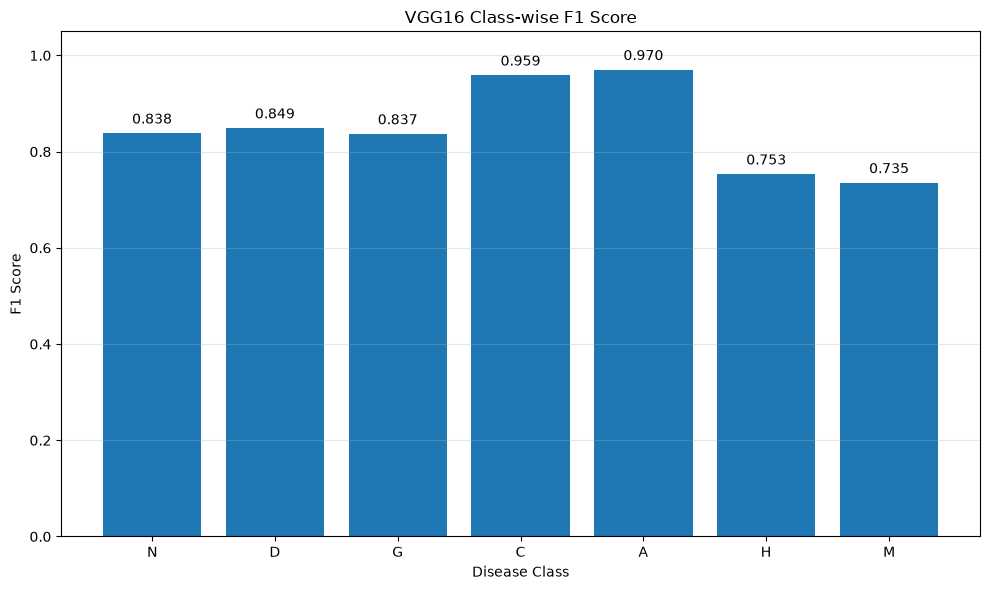

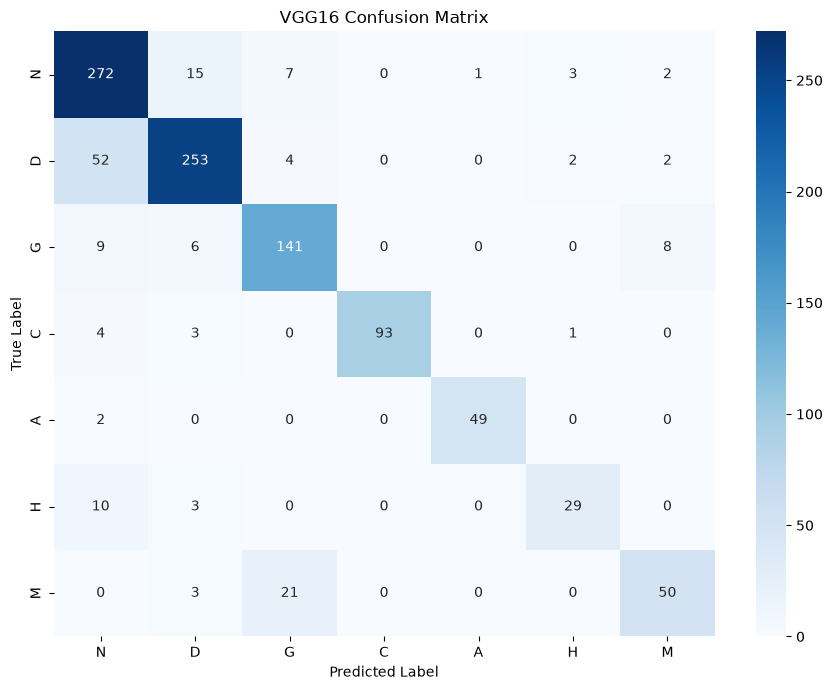

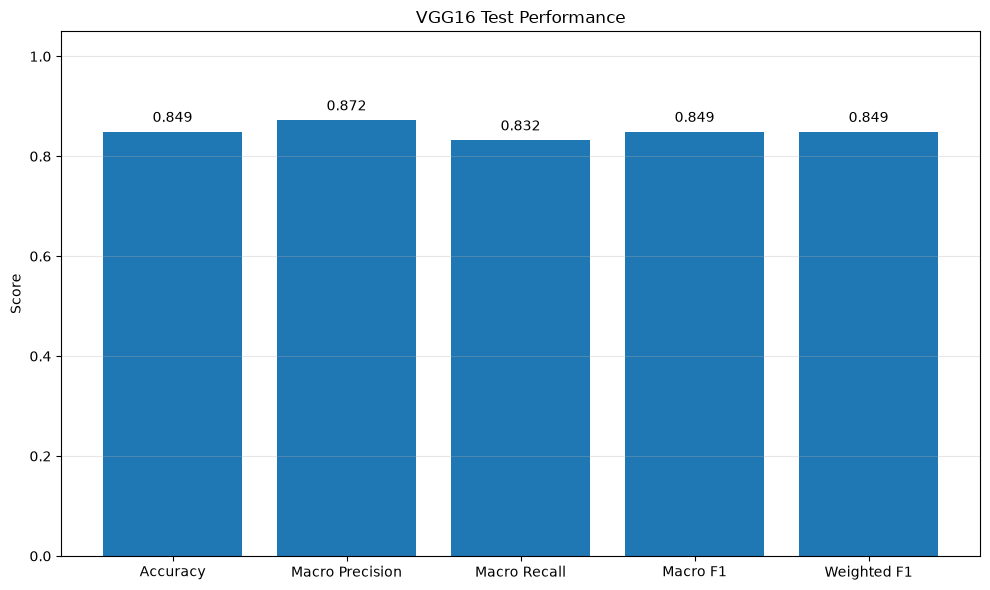



VGG16 EVALUATION COMPLETE

Results saved in:
D:\gpt\OcuVision-AI\results\vgg16

Generated files:
  ✓ vgg16_classification_report.csv
  ✓ vgg16_classwise_f1.csv
  ✓ vgg16_classwise_f1.png
  ✓ vgg16_confusion_matrix.png
  ✓ vgg16_experiment_summary.txt
  ✓ vgg16_test_metrics.csv
  ✓ vgg16_test_metrics.json
  ✓ vgg16_test_metrics.png
  ✓ vgg16_training_curves.png
  ✓ vgg16_training_history.csv

Checkpoint:
  ✓ D:\gpt\OcuVision-AI\models\vgg16_best_checkpoint.pth

FINAL VGG16 METRICS
----------------------------------------
Accuracy        : 84.88%
Macro Precision : 87.19%
Macro Recall    : 83.18%
Macro F1        : 84.88%
Weighted F1     : 84.86%


In [6]:
# ============================================================
# VGG16 COMPLETE EVALUATION + RESULTS
# OcuVision-AI
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torchvision.models import vgg16, VGG16_Weights

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Recreate VGG16 architecture
# ------------------------------------------------------------

print("Loading best VGG16 checkpoint...")

best_model = vgg16(
    weights=None
)

best_model.classifier[6] = nn.Linear(
    best_model.classifier[6].in_features,
    len(classes)
)

best_model = best_model.to(device)

# ------------------------------------------------------------
# 2. Load best checkpoint
# ------------------------------------------------------------

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT_PATH}\n\n"
        "Make sure the VGG16 training cell has finished."
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_model.eval()

print("✓ Best checkpoint loaded")
print(f"Checkpoint epoch: {checkpoint.get('epoch', 'unknown')}")
print(
    f"Best validation Macro F1: "
    f"{checkpoint.get('best_val_macro_f1', 'unknown')}"
)

# ------------------------------------------------------------
# 3. Test-set inference
# ------------------------------------------------------------

all_labels = []
all_predictions = []
all_probabilities = []

test_loss = 0.0

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Evaluating VGG16 on test set"
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if device.type == "cuda":

            with torch.amp.autocast("cuda"):
                outputs = best_model(images)
                loss = criterion(outputs, labels)

        else:

            outputs = best_model(images)
            loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

# Convert to numpy arrays

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

test_loss = test_loss / len(test_loader.dataset)

# ------------------------------------------------------------
# 4. Calculate final metrics
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# 5. Print final test results
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("VGG16 FINAL TEST RESULTS")
print("=" * 70)

print(f"Test Loss          : {test_loss:.4f}")
print(f"Accuracy            : {test_accuracy * 100:.2f}%")
print(f"Macro Precision     : {macro_precision * 100:.2f}%")
print(f"Macro Recall        : {macro_recall * 100:.2f}%")
print(f"Macro F1            : {macro_f1 * 100:.2f}%")
print(f"Weighted F1         : {weighted_f1 * 100:.2f}%")

print("=" * 70)

# ------------------------------------------------------------
# 6. Classification report
# ------------------------------------------------------------

report_dict = classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report_dict
).transpose()

classification_report_path = (
    RESULTS_DIR / "vgg16_classification_report.csv"
)

report_df.to_csv(
    classification_report_path
)

print("\nClassification Report:")
display(report_df.round(4))

# ------------------------------------------------------------
# 7. Class-wise F1 scores
# ------------------------------------------------------------

classwise_f1 = {}

for cls in classes:

    classwise_f1[cls] = report_dict[
        cls
    ]["f1-score"]

classwise_f1_df = pd.DataFrame({
    "Class": list(classwise_f1.keys()),
    "F1 Score": list(classwise_f1.values())
})

classwise_f1_path = (
    RESULTS_DIR / "vgg16_classwise_f1.csv"
)

classwise_f1_df.to_csv(
    classwise_f1_path,
    index=False
)

# Plot class-wise F1

plt.figure(figsize=(10, 6))

plt.bar(
    classwise_f1_df["Class"],
    classwise_f1_df["F1 Score"]
)

plt.ylim(0, 1.05)
plt.xlabel("Disease Class")
plt.ylabel("F1 Score")
plt.title("VGG16 Class-wise F1 Score")

for i, value in enumerate(
    classwise_f1_df["F1 Score"]
):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

classwise_f1_plot = (
    RESULTS_DIR / "vgg16_classwise_f1.png"
)

plt.savefig(
    classwise_f1_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("VGG16 Confusion Matrix")

plt.tight_layout()

confusion_matrix_path = (
    RESULTS_DIR / "vgg16_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. Test metrics plot
# ------------------------------------------------------------

metric_names = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

metric_values = [
    test_accuracy,
    macro_precision,
    macro_recall,
    macro_f1,
    weighted_f1
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    metric_names,
    metric_values
)

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("VGG16 Test Performance")

for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

test_metrics_plot = (
    RESULTS_DIR / "vgg16_test_metrics.png"
)

plt.savefig(
    test_metrics_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. Save numerical metrics
# ------------------------------------------------------------

metrics = {
    "model": "VGG16",
    "test_loss": float(test_loss),
    "accuracy": float(test_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "best_validation_macro_f1": float(
        checkpoint["best_val_macro_f1"]
    ),
    "best_epoch": int(
        checkpoint["epoch"]
    ),
    "test_samples": int(
        len(test_dataset)
    )
}

metrics_df = pd.DataFrame([
    metrics
])

metrics_csv_path = (
    RESULTS_DIR / "vgg16_test_metrics.csv"
)

metrics_df.to_csv(
    metrics_csv_path,
    index=False
)

# Also save JSON

metrics_json_path = (
    RESULTS_DIR / "vgg16_test_metrics.json"
)

with open(
    metrics_json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metrics,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 11. Experiment summary
# ------------------------------------------------------------

summary_text = f"""
VGG16 Experiment Summary
=========================

Model:
VGG16 pretrained on ImageNet

Dataset:
ODIR-5K preprocessed ocular disease dataset

Classes:
{", ".join(classes)}

Dataset split:
Train: {len(train_dataset)}
Validation: {len(val_dataset)}
Test: {len(test_dataset)}

Random seed:
{SEED}

Input size:
224 x 224

Batch size:
{BATCH_SIZE}

Optimizer:
AdamW

Learning rate:
1e-4

Weight decay:
1e-4

Number of epochs:
{NUM_EPOCHS}

Best validation epoch:
{checkpoint["epoch"]}

Best validation Macro F1:
{checkpoint["best_val_macro_f1"] * 100:.2f}%

Final Test Results
------------------

Test Loss:
{test_loss:.4f}

Accuracy:
{test_accuracy * 100:.2f}%

Macro Precision:
{macro_precision * 100:.2f}%

Macro Recall:
{macro_recall * 100:.2f}%

Macro F1:
{macro_f1 * 100:.2f}%

Weighted F1:
{weighted_f1 * 100:.2f}%
"""

summary_path = (
    RESULTS_DIR / "vgg16_experiment_summary.txt"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(summary_text)

# ------------------------------------------------------------
# 12. Final file listing
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("VGG16 EVALUATION COMPLETE")
print("=" * 70)

print("\nResults saved in:")
print(RESULTS_DIR)

print("\nGenerated files:")

for file in sorted(RESULTS_DIR.iterdir()):

    if file.is_file():
        print("  ✓", file.name)

print("\nCheckpoint:")
print("  ✓", CHECKPOINT_PATH)

print("\nFINAL VGG16 METRICS")
print("-" * 40)

print(f"Accuracy        : {test_accuracy * 100:.2f}%")
print(f"Macro Precision : {macro_precision * 100:.2f}%")
print(f"Macro Recall    : {macro_recall * 100:.2f}%")
print(f"Macro F1        : {macro_f1 * 100:.2f}%")
print(f"Weighted F1     : {weighted_f1 * 100:.2f}%")

print("=" * 70)

In [5]:
# ============================================================
# VGG16 XAI — RECREATE EXACT ORIGINAL TEST SPLIT
# ============================================================

from pathlib import Path
import pandas as pd

from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------

ROOT = Path(r"D:\gpt\OcuVision-AI")

DATA_DIR = ROOT / "data" / "preprocessed"

RESULTS_DIR = ROOT / "results" / "vgg16"

CHECKPOINT_PATH = (
    ROOT / "models" / "vgg16_best_checkpoint.pth"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Random seed
# ------------------------------------------------------------

SEED = 42


# ------------------------------------------------------------
# 3. Device
# ------------------------------------------------------------

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ------------------------------------------------------------
# 4. Class mapping
# ------------------------------------------------------------

classes = [
    "N",
    "D",
    "G",
    "C",
    "A",
    "H",
    "M"
]

class_to_idx = {
    cls: idx
    for idx, cls in enumerate(classes)
}

idx_to_class = {
    idx: cls
    for cls, idx in class_to_idx.items()
}


# ------------------------------------------------------------
# 5. Collect image paths
# ------------------------------------------------------------

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_DIR}"
    )

image_paths = []
labels = []

for cls in classes:

    class_dir = DATA_DIR / cls

    if not class_dir.exists():
        raise FileNotFoundError(
            f"Missing class directory: {class_dir}"
        )

    for image_path in sorted(
        class_dir.glob("*")
    ):

        if image_path.suffix.lower() in [
            ".jpg",
            ".jpeg",
            ".png",
            ".bmp",
            ".webp"
        ]:

            image_paths.append(
                str(image_path)
            )

            labels.append(
                class_to_idx[cls]
            )


df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

df["class"] = df["label"].map(
    idx_to_class
)


# ------------------------------------------------------------
# 6. Recreate EXACT 80/10/10 split
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)


# ------------------------------------------------------------
# 7. Reset indexes
# ------------------------------------------------------------

train_df = train_df.reset_index(
    drop=True
)

val_df = val_df.reset_index(
    drop=True
)

test_df = test_df.reset_index(
    drop=True
)


# ------------------------------------------------------------
# 8. Evaluation transform
# ------------------------------------------------------------

from torchvision import transforms

eval_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


# ------------------------------------------------------------
# 9. Verify split
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXACT VGG16 TEST SPLIT RECREATED")
print("=" * 70)

print(
    f"Total images : {len(df)}"
)

print(
    f"Train images : {len(train_df)}"
)

print(
    f"Val images   : {len(val_df)}"
)

print(
    f"Test images  : {len(test_df)}"
)

print("\nTest class distribution:")

print(
    test_df["class"]
    .value_counts()
    .reindex(classes)
)

print("\n✓ test_df is ready")
print("=" * 70)

Device: cuda

EXACT VGG16 TEST SPLIT RECREATED
Total images : 10449
Train images : 8359
Val images   : 1045
Test images  : 1045

Test class distribution:
class
N    300
D    313
G    164
C    101
A     51
H     42
M     74
Name: count, dtype: int64

✓ test_df is ready


01/10 | True: C | Predicted: C | Confidence: 100.00%
02/10 | True: G | Predicted: G | Confidence: 97.48%
03/10 | True: D | Predicted: D | Confidence: 99.99%
04/10 | True: M | Predicted: M | Confidence: 61.41%
05/10 | True: D | Predicted: D | Confidence: 100.00%
06/10 | True: D | Predicted: D | Confidence: 52.43%
07/10 | True: D | Predicted: D | Confidence: 99.79%
08/10 | True: G | Predicted: G | Confidence: 95.86%
09/10 | True: N | Predicted: N | Confidence: 87.48%
10/10 | True: D | Predicted: G | Confidence: 78.06%


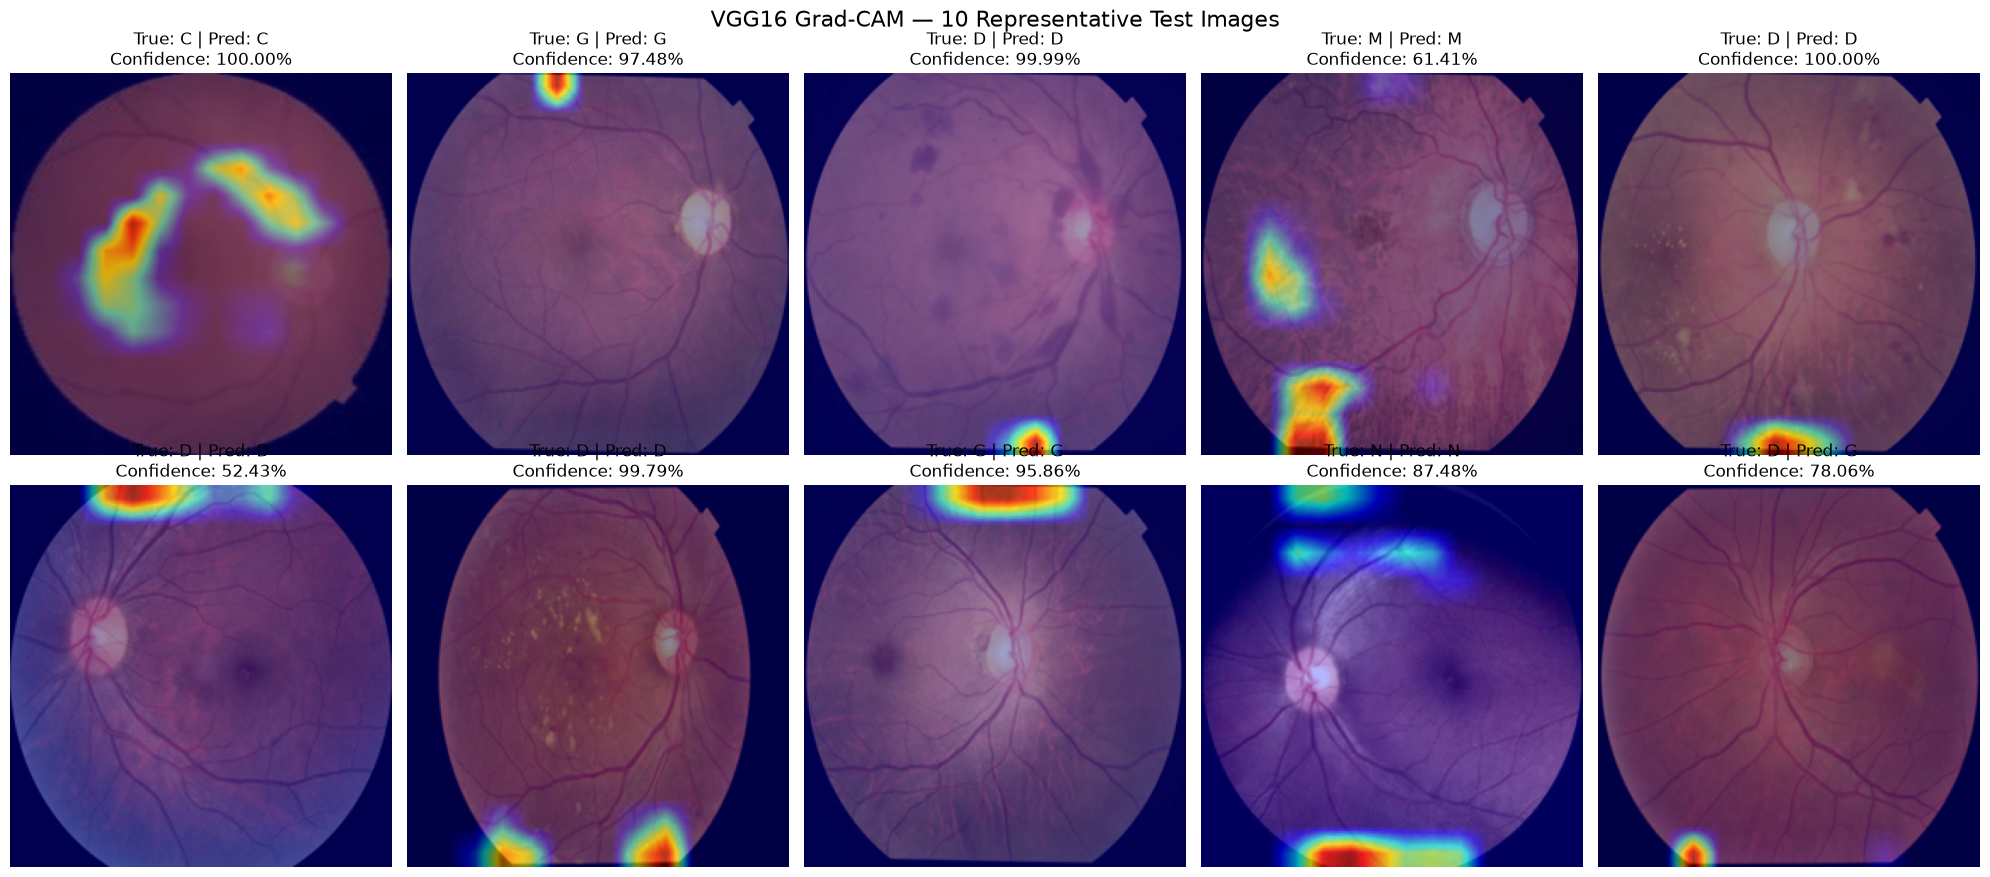



VGG16 GRAD-CAM COMPLETE
Images generated: 10
Correct predictions: 9/10
Grad-CAM directory: D:\gpt\OcuVision-AI\results\vgg16\gradcam
Summary CSV: D:\gpt\OcuVision-AI\results\vgg16\gradcam\gradcam_summary.csv
Contact sheet: D:\gpt\OcuVision-AI\results\vgg16\gradcam\vgg16_gradcam_contact_sheet.png


In [6]:
# ============================================================
# VGG16 GRAD-CAM / XAI
# 10 REPRESENTATIVE TEST IMAGES
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image
from torchvision.models import vgg16

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

GRADCAM_DIR = RESULTS_DIR / "gradcam"
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# LOAD VGG16 CHECKPOINT
# ------------------------------------------------------------

cam_model = vgg16(weights=None)

cam_model.classifier[6] = nn.Linear(
    cam_model.classifier[6].in_features,
    len(classes)
)

cam_model = cam_model.to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

cam_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

cam_model.eval()


# ------------------------------------------------------------
# DISABLE IN-PLACE RELU
# Prevents Grad-CAM backward-hook issues
# ------------------------------------------------------------

for module in cam_model.modules():
    if isinstance(module, nn.ReLU):
        module.inplace = False


# ------------------------------------------------------------
# GRAD-CAM TARGET LAYER
# VGG16 final convolutional layer = features[28]
# ------------------------------------------------------------

target_layers = [cam_model.features[28]]

cam = GradCAM(
    model=cam_model,
    target_layers=target_layers
)


# ------------------------------------------------------------
# SELECT 10 REPRESENTATIVE TEST IMAGES
# ------------------------------------------------------------

num_samples = min(10, len(test_df))

sample_indices = np.linspace(
    0,
    len(test_df) - 1,
    num_samples,
    dtype=int
)

selected_test_df = (
    test_df.iloc[sample_indices]
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# GENERATE GRAD-CAM
# ------------------------------------------------------------

gradcam_records = []


for sample_number in range(1, num_samples + 1):

    row = selected_test_df.iloc[sample_number - 1]

    image_path = Path(row["image_path"])
    true_class = row["class"]

    # Load original image
    original_image = Image.open(
        image_path
    ).convert("RGB")

    # Resize for VGG16
    resized_image = original_image.resize(
        (224, 224)
    )

    # RGB image for visualization
    rgb_image = (
        np.array(resized_image)
        .astype(np.float32)
        / 255.0
    )

    # Model input
    input_tensor = (
        eval_transform(resized_image)
        .unsqueeze(0)
        .to(device)
    )

    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    with torch.no_grad():

        outputs = cam_model(input_tensor)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predicted_index = torch.argmax(
            probabilities,
            dim=1
        ).item()

        predicted_class = idx_to_class[
            predicted_index
        ]

        confidence = probabilities[
            0,
            predicted_index
        ].item()

    # --------------------------------------------------------
    # GRAD-CAM
    # --------------------------------------------------------

    targets = [
        ClassifierOutputTarget(predicted_index)
    ]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    visualization = show_cam_on_image(
        rgb_image,
        grayscale_cam,
        use_rgb=True
    )

    # --------------------------------------------------------
    # SAVE RESULT
    # --------------------------------------------------------

    output_filename = (
        f"{sample_number:02d}_"
        f"{true_class}_"
        f"{predicted_class}_"
        f"{confidence * 100:.2f}.png"
    )

    output_path = GRADCAM_DIR / output_filename

    Image.fromarray(
        visualization
    ).save(output_path)

    # --------------------------------------------------------
    # RECORD
    # --------------------------------------------------------

    gradcam_records.append({

        "sample": sample_number,

        "image_path": str(image_path),

        "true_class": true_class,

        "predicted_class": predicted_class,

        "confidence": confidence,

        "correct": predicted_class == true_class,

        "gradcam_path": str(output_path)
    })

    print(
        f"{sample_number:02d}/{num_samples} | "
        f"True: {true_class} | "
        f"Predicted: {predicted_class} | "
        f"Confidence: {confidence * 100:.2f}%"
    )


# ------------------------------------------------------------
# SAVE SUMMARY CSV
# ------------------------------------------------------------

gradcam_df = pd.DataFrame(
    gradcam_records
)

gradcam_csv = (
    GRADCAM_DIR /
    "gradcam_summary.csv"
)

gradcam_df.to_csv(
    gradcam_csv,
    index=False
)


# ------------------------------------------------------------
# CREATE CONTACT SHEET
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    5,
    figsize=(20, 9)
)

axes = axes.flatten()


for ax, record in zip(
    axes,
    gradcam_records
):

    image = Image.open(
        record["gradcam_path"]
    )

    ax.imshow(image)

    ax.set_title(
        f"True: {record['true_class']} | "
        f"Pred: {record['predicted_class']}\n"
        f"Confidence: "
        f"{record['confidence'] * 100:.2f}%"
    )

    ax.axis("off")


plt.suptitle(
    "VGG16 Grad-CAM — 10 Representative Test Images",
    fontsize=16
)

plt.tight_layout()


contact_sheet_path = (
    GRADCAM_DIR /
    "vgg16_gradcam_contact_sheet.png"
)

plt.savefig(
    contact_sheet_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

correct_count = int(
    gradcam_df["correct"].sum()
)

print("\n")
print("=" * 70)
print("VGG16 GRAD-CAM COMPLETE")
print("=" * 70)

print(
    f"Images generated: "
    f"{len(gradcam_df)}"
)

print(
    f"Correct predictions: "
    f"{correct_count}/{len(gradcam_df)}"
)

print(
    f"Grad-CAM directory: "
    f"{GRADCAM_DIR}"
)

print(
    f"Summary CSV: "
    f"{gradcam_csv}"
)

print(
    f"Contact sheet: "
    f"{contact_sheet_path}"
)

print("=" * 70)

VGG16 EXTERNAL IMAGE INFERENCE
External image folder:
D:\gpt\OcuVision-AI\data\external_images

No external image found.
Creating a demo image from the existing dataset...

Demo image created:
D:\gpt\OcuVision-AI\data\external_images\demo_fundus_image.jpg

NOTE: This is only a pipeline/demo image.
It is NOT an external validation image.
It remains separate from the official test evaluation.

Loading VGG16 checkpoint...
VGG16 checkpoint loaded successfully.

Image:
demo_fundus_image.jpg
Original image size: (512, 512)


VGG16 PREDICTION
Predicted class : A
Confidence      : 92.70%

All class probabilities:
----------------------------------------
N: 0.66%
D: 4.55%
G: 0.33%
C: 0.06%
A: 92.70%
H: 1.50%
M: 0.20%

Generating Grad-CAM...


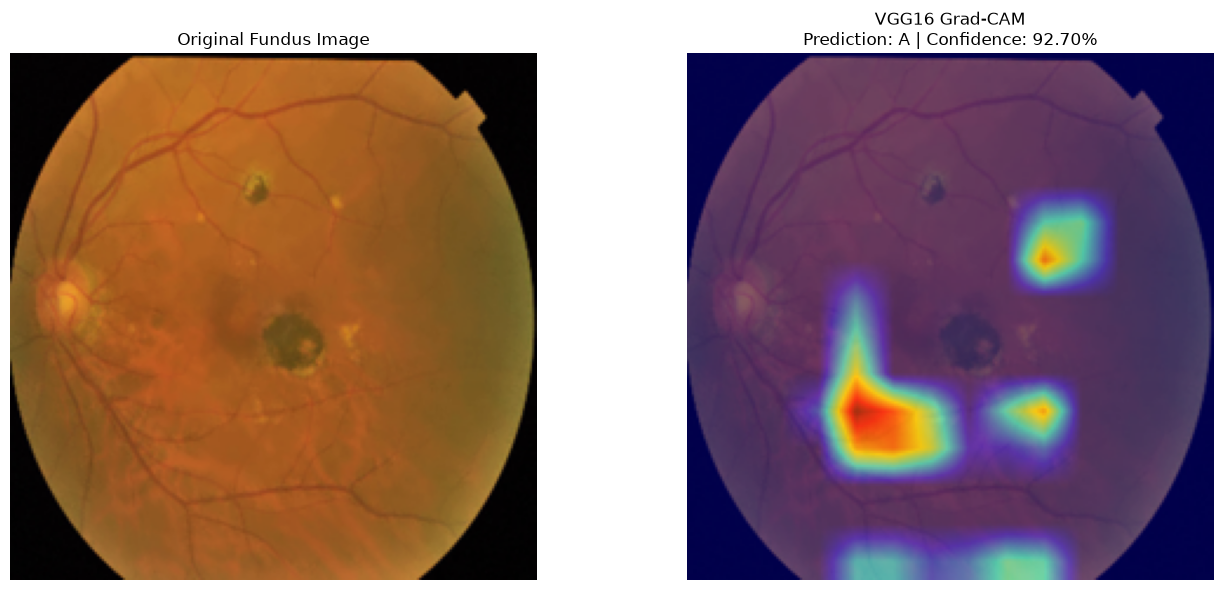



VGG16 EXTERNAL INFERENCE COMPLETE
Image       : demo_fundus_image.jpg
Prediction  : A
Confidence  : 92.70%

Grad-CAM saved to:
D:\gpt\OcuVision-AI\results\vgg16\external_xai\vgg16_external_demo_fundus_image_A_92.70.png

Probabilities saved to:
D:\gpt\OcuVision-AI\results\vgg16\external_xai\vgg16_external_demo_fundus_image_probabilities.csv


In [9]:
# ============================================================
# VGG16 EXTERNAL IMAGE INFERENCE + GRAD-CAM
# COMPLETE AUTOMATIC VERSION
# ============================================================

from pathlib import Path
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image
from torchvision.models import vgg16

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


# ============================================================
# 1. PATHS
# ============================================================

EXTERNAL_DIR = ROOT / "data" / "external_images"

EXTERNAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 70)
print("VGG16 EXTERNAL IMAGE INFERENCE")
print("=" * 70)

print(f"External image folder:")
print(EXTERNAL_DIR)


# ============================================================
# 2. FIND IMAGE RECURSIVELY
# ============================================================

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

external_images = sorted(
    [
        p
        for p in EXTERNAL_DIR.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    ]
)


# ============================================================
# 3. IF EXTERNAL FOLDER IS EMPTY:
#    CREATE A DEMO IMAGE AUTOMATICALLY
# ============================================================

if len(external_images) == 0:

    print("\nNo external image found.")
    print("Creating a demo image from the existing dataset...")
    
    dataset_images = sorted(
        [
            p
            for p in DATA_DIR.rglob("*")
            if p.is_file()
            and p.suffix.lower() in image_extensions
        ]
    )

    if len(dataset_images) == 0:
        raise FileNotFoundError(
            "No images were found anywhere in:\n"
            f"{DATA_DIR}"
        )

    source_image = dataset_images[0]

    demo_image_path = (
        EXTERNAL_DIR /
        "demo_fundus_image.jpg"
    )

    shutil.copy2(
        source_image,
        demo_image_path
    )

    EXTERNAL_IMAGE_PATH = demo_image_path

    print("\nDemo image created:")
    print(EXTERNAL_IMAGE_PATH)

    print(
        "\nNOTE: This is only a pipeline/demo image."
        "\nIt is NOT an external validation image."
        "\nIt remains separate from the official test evaluation."
    )

else:

    EXTERNAL_IMAGE_PATH = external_images[0]

    print("\nExternal image found:")
    print(EXTERNAL_IMAGE_PATH)


# ============================================================
# 4. LOAD VGG16 MODEL
# ============================================================

print("\nLoading VGG16 checkpoint...")

external_model = vgg16(
    weights=None
)

external_model.classifier[6] = nn.Linear(
    external_model.classifier[6].in_features,
    len(classes)
)


# ------------------------------------------------------------
# Disable inplace ReLU for Grad-CAM
# ------------------------------------------------------------

for module in external_model.modules():

    if isinstance(module, nn.ReLU):

        module.inplace = False


external_model = external_model.to(device)


# ============================================================
# 5. LOAD CHECKPOINT
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

external_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

external_model.eval()


print("VGG16 checkpoint loaded successfully.")


# ============================================================
# 6. LOAD IMAGE
# ============================================================

original_image = Image.open(
    EXTERNAL_IMAGE_PATH
).convert("RGB")


print("\nImage:")
print(EXTERNAL_IMAGE_PATH.name)

print(
    f"Original image size: "
    f"{original_image.size}"
)


# ============================================================
# 7. RESIZE IMAGE
# ============================================================

resized_image = original_image.resize(
    (224, 224)
)

rgb_image = (
    np.array(resized_image)
    .astype(np.float32)
    / 255.0
)


# ============================================================
# 8. APPLY SAME TRANSFORM USED FOR VGG16
# ============================================================

input_tensor = (
    eval_transform(resized_image)
    .unsqueeze(0)
    .to(device)
)


# ============================================================
# 9. PREDICTION
# ============================================================

with torch.no_grad():

    outputs = external_model(
        input_tensor
    )

    probabilities = torch.softmax(
        outputs,
        dim=1
    )[0]

    predicted_index = torch.argmax(
        probabilities
    ).item()

    predicted_class = idx_to_class[
        predicted_index
    ]

    confidence = probabilities[
        predicted_index
    ].item()


# ============================================================
# 10. PRINT PREDICTION
# ============================================================

print("\n")
print("=" * 70)
print("VGG16 PREDICTION")
print("=" * 70)

print(
    f"Predicted class : {predicted_class}"
)

print(
    f"Confidence      : "
    f"{confidence * 100:.2f}%"
)

print("=" * 70)


# ============================================================
# 11. PRINT ALL 7 CLASS PROBABILITIES
# ============================================================

print("\nAll class probabilities:")
print("-" * 40)

probability_records = []

for index, class_name in enumerate(classes):

    probability = probabilities[
        index
    ].item()

    probability_records.append({
        "class": class_name,
        "probability": probability
    })

    print(
        f"{class_name}: "
        f"{probability * 100:.2f}%"
    )


# ============================================================
# 12. GRAD-CAM
# ============================================================

print("\nGenerating Grad-CAM...")


# VGG16 final convolutional layer
target_layers = [
    external_model.features[28]
]


external_cam = GradCAM(
    model=external_model,
    target_layers=target_layers
)


targets = [
    ClassifierOutputTarget(
        predicted_index
    )
]


grayscale_cam = external_cam(
    input_tensor=input_tensor,
    targets=targets
)[0]


# ============================================================
# 13. CREATE GRAD-CAM VISUALIZATION
# ============================================================

visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)


# ============================================================
# 14. DISPLAY ORIGINAL + GRAD-CAM
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)


axes[0].imshow(
    resized_image
)

axes[0].set_title(
    "Original Fundus Image"
)

axes[0].axis("off")


axes[1].imshow(
    visualization
)

axes[1].set_title(
    f"VGG16 Grad-CAM\n"
    f"Prediction: {predicted_class} | "
    f"Confidence: {confidence * 100:.2f}%"
)

axes[1].axis("off")


plt.tight_layout()

plt.show()


# ============================================================
# 15. SAVE RESULTS
# ============================================================

EXTERNAL_XAI_DIR = (
    RESULTS_DIR /
    "external_xai"
)

EXTERNAL_XAI_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Save Grad-CAM image
# ------------------------------------------------------------

output_path = (
    EXTERNAL_XAI_DIR /
    f"vgg16_external_"
    f"{EXTERNAL_IMAGE_PATH.stem}_"
    f"{predicted_class}_"
    f"{confidence * 100:.2f}.png"
)


Image.fromarray(
    visualization
).save(
    output_path
)


# ------------------------------------------------------------
# Save probabilities CSV
# ------------------------------------------------------------

probability_df = pd.DataFrame(
    probability_records
)

probability_csv = (
    EXTERNAL_XAI_DIR /
    f"vgg16_external_"
    f"{EXTERNAL_IMAGE_PATH.stem}_"
    f"probabilities.csv"
)

probability_df.to_csv(
    probability_csv,
    index=False
)


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("VGG16 EXTERNAL INFERENCE COMPLETE")
print("=" * 70)

print(
    f"Image       : "
    f"{EXTERNAL_IMAGE_PATH.name}"
)

print(
    f"Prediction  : "
    f"{predicted_class}"
)

print(
    f"Confidence  : "
    f"{confidence * 100:.2f}%"
)

print(
    f"\nGrad-CAM saved to:"
)

print(output_path)

print(
    f"\nProbabilities saved to:"
)

print(probability_csv)

print("=" * 70)